# EDA 01 · Datos en bruto: calidad, fallos de sensores y selección de 200 puntos urbanos

**Encargo (hueco 4):** prever la intensidad diaria de tráfico a 7 días en ~200 puntos urbanos de Madrid para
planificar obras en vía urbana. Histórico máximo: 2 años (nov-2024 → oct-2026).

**Qué hace este notebook**
1. Descarga los datos desde código y los consulta **en bruto** (una fila por sensor y cuarto de hora).
2. Aparta la **última semana como test** antes de mirar nada.
3. Mide el tamaño del dataset y se queda con los **puntos urbanos**.
4. Controla la calidad: duplicados, nulos, ceros y valores imposibles.
5. Cuenta **cuántos sensores fallan** y de qué forma, y cruza con el fichero de ubicación para las altas y bajas.
6. Elige los **200 sensores** con los que se trabaja en el resto del proyecto.

> **Sin data snooping.** La semana de test (25–31 oct 2026) se fija por calendario y todas las consultas filtran
> `fecha < 2026-10-25`. Ninguna cifra, gráfico ni decisión de este notebook usa esa semana.

Los 24 meses en bruto suman ~320 M de filas y no caben en memoria con pandas. Por eso se consultan con **DuckDB**
directamente sobre los Parquet: solo se trae a pandas lo ya resumido.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap


def _raiz() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p, p / "e1"):
            if (c / "src" / "descarga_bruto.py").exists():
                return c
    raise FileNotFoundError("No encuentro e1/src/descarga_bruto.py")


RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))
import descarga_bruto  # noqa: E402

BRUTO = RAIZ / "data" / "bruto"
SELECCION = RAIZ / "data" / "seleccion"
SELECCION.mkdir(parents=True, exist_ok=True)

DESDE, HASTA = "2024-11", "2026-10"
DIAS_TEST = 7
N_SENSORES = 200
SEMILLA = 42
INTENSIDAD_MAX = 15_000  # veh/h; por encima es un error de equipo (ver sección 3)

INICIO = pd.Period(DESDE, freq="M").start_time
FIN = pd.Period(HASTA, freq="M").end_time.normalize()
TEST_INICIO = FIN - pd.Timedelta(days=DIAS_TEST - 1)
DIAS = pd.date_range(INICIO, TEST_INICIO - pd.Timedelta(days=1), freq="D")

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Entrenamiento: {DIAS[0]:%Y-%m-%d} → {DIAS[-1]:%Y-%m-%d}  ({len(DIAS)} días)")
print(f"Test:          {TEST_INICIO:%Y-%m-%d} → {FIN:%Y-%m-%d}  ({DIAS_TEST} días, no se usa aquí)")

Entrenamiento: 2024-11-01 → 2026-10-24  (723 días)
Test:          2026-10-25 → 2026-10-31  (7 días, no se usa aquí)


## 1. Descarga

`src/descarga_bruto.py` descarga cada mes del portal de datos abiertos y lo pasa a Parquet sin filtrar ni agregar.
Si los meses ya están en `data/bruto/`, no vuelve a descargarlos.

In [2]:
descarga_bruto.descargar_ubicacion(DESDE, HASTA, BRUTO)
descarga_bruto.descargar_trafico(DESDE, HASTA, BRUTO)

Ubicación: hecho. Meses sin fichero en el portal: ninguno
Tráfico: 24 meses, 24 ya convertidos.


## 2. Separación del test y tamaño del dataset

Se definen dos vistas de DuckDB sobre los Parquet. Las dos excluyen la semana de test, así que todo lo que sigue
trabaja solo con entrenamiento:
- `bruto`: todos los puntos de medida.
- `urb`: solo los puntos urbanos (`tipo_elem = 'URB'`).

In [3]:
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
ficheros = (BRUTO / "trafico" / "*.parquet").as_posix()
con.execute(f"""
    CREATE VIEW bruto AS
    SELECT * FROM read_parquet('{ficheros}')
    WHERE fecha < TIMESTAMP '{TEST_INICIO:%Y-%m-%d}'
""")
con.execute("CREATE VIEW urb AS SELECT * FROM bruto WHERE tipo_elem = 'URB'")

ultima = con.execute("SELECT max(fecha) FROM bruto").fetchall()[0][0]
assert ultima < TEST_INICIO, "La semana de test se ha colado en el entrenamiento"
print(f"Última lectura usada: {ultima}")

Última lectura usada: 2026-10-24 23:45:00


In [4]:
por_tipo = con.sql("""
    SELECT tipo_elem, count(*) AS filas, count(DISTINCT id) AS sensores
    FROM bruto GROUP BY 1 ORDER BY 2 DESC
""").df().set_index("tipo_elem")
por_tipo["% filas"] = por_tipo["filas"] / por_tipo["filas"].sum() * 100

disco = sum(f.stat().st_size for f in (BRUTO / "trafico").glob("*.parquet")) / 1e9
print(f"Parquet en disco (24 meses): {disco:.2f} GB  ·  columnas: {con.sql('DESCRIBE bruto').df()['column_name'].tolist()}")
por_tipo

Parquet en disco (24 meses): 1.07 GB  ·  columnas: ['id', 'fecha', 'tipo_elem', 'intensidad', 'ocupacion', 'carga', 'vmed', 'error', 'periodo_integracion']


,filas,sensores,% filas
tipo_elem,,,
URB,286726917,4499,91.18
M30,20216893,318,6.43
C30,7527035,149,2.39


**Lectura.** El bruto mezcla tres tipos de punto. `URB` son los puntos urbanos; `M30` y `C30` son la M-30 y sus
accesos, vías rápidas de otra naturaleza. El encargo habla de obras en **vía urbana**, así que nos quedamos solo con
`URB`. La M-30 se conserva en disco por si en E2 sirve como variable externa.

## 3. Calidad del bruto urbano

### 3.1 Duplicados, nulos y columnas

In [5]:
resumen = con.sql("""
    SELECT count(*) AS filas,
           count(*) - count(DISTINCT (id, fecha)) AS duplicados_id_fecha,
           count(DISTINCT id) AS sensores,
           min(fecha) AS desde, max(fecha) AS hasta
    FROM urb
""").df().T.rename(columns={0: "valor"})
resumen

,valor
filas,286726917
duplicados_id_fecha,0
sensores,4499
desde,2024-11-01 00:00:00
hasta,2026-10-24 23:45:00


In [6]:
columnas = con.sql("DESCRIBE urb").df()["column_name"].tolist()
nulos = con.sql("SELECT " + ", ".join(f"count(*) - count({c}) AS {c}" for c in columnas) + " FROM urb").df()
nulos.T.rename(columns={0: "nulos (NaN)"})

,nulos (NaN)
id,0
fecha,0
tipo_elem,0
intensidad,0
ocupacion,2
carga,0
vmed,0
error,0
periodo_integracion,0


In [7]:
print("Valores de 'error':", con.sql("SELECT error, count(*) n FROM urb GROUP BY 1").df().values.tolist())
print("Minutos de las lecturas:", con.sql("SELECT DISTINCT minute(fecha) m FROM urb ORDER BY 1").df()["m"].tolist())
con.sql("""
    SELECT 'intensidad' AS columna, min(intensidad) AS min, max(intensidad) AS max FROM urb UNION ALL
    SELECT 'ocupacion', min(ocupacion), max(ocupacion) FROM urb UNION ALL
    SELECT 'carga', min(carga), max(carga) FROM urb UNION ALL
    SELECT 'vmed', min(vmed), max(vmed) FROM urb
""").df()

Valores de 'error': [['N', 286726917]]


Minutos de las lecturas: [0, 15, 30, 45]


,columna,min,max
0,intensidad,0,99999
1,ocupacion,0,100
2,carga,0,100
3,vmed,0,0


**Lectura.**
- No hay filas duplicadas (mismo sensor y misma hora) ni ningún `NaN`. Los fallos **no aparecen como nulos
  explícitos**: aparecen como filas que faltan, ceros o valores imposibles. Se analizan en las secciones 4 y 5.
- La columna `error` vale siempre `N` en los puntos urbanos, así que **no sirve** para detectar fallos.
- `vmed` (velocidad media) vale siempre 0: los puntos urbanos no miden velocidad. No la usaremos.
- Las lecturas caen en los minutos 0, 15, 30 y 45: la frecuencia nativa es de 15 minutos.

### 3.2 Valores imposibles de intensidad

In [8]:
rangos = con.sql(f"""
    SELECT CASE WHEN intensidad = 0 THEN '0'
                WHEN intensidad <= 5000 THEN '1 – 5.000'
                WHEN intensidad <= {INTENSIDAD_MAX} THEN '5.001 – 15.000'
                ELSE '> 15.000' END AS rango,
           count(*) AS lecturas
    FROM urb GROUP BY 1
""").df().set_index("rango").loc[["0", "1 – 5.000", "5.001 – 15.000", "> 15.000"]]
rangos["%"] = rangos["lecturas"] / rangos["lecturas"].sum() * 100
cuantiles = con.execute("SELECT quantile_cont(intensidad, [0.5, 0.9, 0.99, 0.999, 0.9999]) q FROM urb").fetchall()[0][0]
print("Percentiles 50 / 90 / 99 / 99,9 / 99,99 de intensidad (veh/h):", [round(q) for q in cuantiles])
print(con.sql(f"SELECT intensidad, count(*) n FROM urb WHERE intensidad > {INTENSIDAD_MAX} "
              "GROUP BY 1 ORDER BY 2 DESC LIMIT 5").df().to_string(index=False))
rangos

Percentiles 50 / 90 / 99 / 99,9 / 99,99 de intensidad (veh/h): [141, 672, 1650, 2556, 3452]


 intensidad  n
      17880 18
      91500  4
      80273  3
      18667  2
      89090  2


,lecturas,%
rango,,
0,5979515,2.09
1 – 5.000,280743773,97.91
5.001 – 15.000,2317,0.00
> 15.000,1312,0.00


**Decisión.** La intensidad es un caudal en vehículos/hora. El 99,99 % de las lecturas está por debajo de ~3.500
veh/h, y una calle urbana no supera ese orden de magnitud. Las lecturas por **encima de 15.000 veh/h** (incluido el
código 99999) se tratan como **error de equipo**: no se usan para calcular la intensidad y cuentan como lectura no
válida. Son muy pocas, así que no afectan al resultado. Los ceros se tratan aparte en la sección 5, porque un cero
puede ser real (de madrugada) o un sensor caído.

### 3.3 Periodo de integración

Lecturas con periodo_integracion = 15: 74.0%


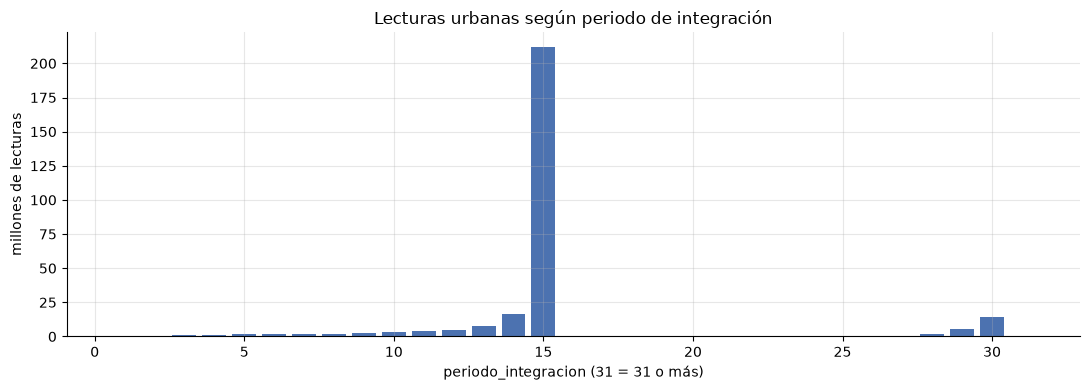

In [9]:
pi = con.sql("""
    SELECT least(periodo_integracion, 31) AS periodo, count(*) AS lecturas, avg(intensidad) AS intensidad_media
    FROM urb GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots()
ax.bar(pi["periodo"], pi["lecturas"] / 1e6, color="#4C72B0")
ax.set(title="Lecturas urbanas según periodo de integración", xlabel="periodo_integracion (31 = 31 o más)",
       ylabel="millones de lecturas")
plt.tight_layout()
print(f"Lecturas con periodo_integracion = 15: {pi.loc[pi['periodo'] == 15, 'lecturas'].sum() / pi['lecturas'].sum():.1%}")

**Lectura.** `periodo_integracion` indica sobre cuánto tiempo se ha integrado la medida. La mayoría vale 15 (el
cuarto de hora completo). Los valores menores corresponden a medidas parciales, y los cercanos a 30 a periodos más
largos. El valor de intensidad sigue siendo un caudal en veh/h, así que no se descartan estas lecturas, pero se
cuentan por día (`n_parcial`) por si hicieran falta en E2.

## 4. Del cuarto de hora al día: tabla de control

Para contar fallos se resume el bruto urbano en **una fila por sensor y día**, con contadores de calidad. No es aún
la serie a modelizar, sino una tabla para medir cuántas lecturas llegan y cómo son. Se calcula en DuckDB y solo el
resultado (~3 M de filas) pasa a pandas.

In [10]:
control = con.sql(f"""
    SELECT id,
           CAST(fecha AS DATE) AS ds,
           count(*)::INT AS n_lect,
           sum((intensidad > {INTENSIDAD_MAX})::INT)::INT AS n_imposible,
           sum((intensidad = 0)::INT)::INT AS n_cero,
           sum((hour(fecha) BETWEEN 7 AND 21)::INT)::INT AS n_lect_dia,
           sum((intensidad = 0 AND hour(fecha) BETWEEN 7 AND 21)::INT)::INT AS n_cero_dia,
           sum((periodo_integracion < 15)::INT)::INT AS n_parcial,
           min(intensidad) FILTER (WHERE intensidad <= {INTENSIDAD_MAX}) AS int_min,
           max(intensidad) FILTER (WHERE intensidad <= {INTENSIDAD_MAX}) AS int_max,
           avg(intensidad) FILTER (WHERE intensidad <= {INTENSIDAD_MAX}) AS int_media
    FROM urb
    GROUP BY ALL
""").df()
control["ds"] = pd.to_datetime(control["ds"])
control["n_valid"] = control["n_lect"] - control["n_imposible"]
print(f"{len(control):,} filas sensor-día · {control['id'].nunique():,} sensores · "
      f"{control.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
control.head()

3,077,000 filas sensor-día · 4,499 sensores · 178 MB


,id,ds,n_lect,n_imposible,n_cero,n_lect_dia,n_cero_dia,n_parcial,int_min,int_max,int_media,n_valid
0,4309,2024-11-03,96,0,0,60,0,3,452,904,687.42,96
1,4309,2024-11-15,96,0,0,60,0,6,372,944,752.21,96
2,4311,2024-11-05,96,0,0,60,0,33,12,168,49.08,96
3,4316,2024-11-19,96,0,0,60,0,9,24,624,316.00,96
4,4317,2024-11-19,96,0,0,60,0,5,112,1800,"1,021.09",96


### 4.1 Lecturas esperadas por día
Un día completo tiene 96 cuartos de hora. Los días de cambio de hora tienen 23 h (marzo) o 25 h (octubre). Se
comprueba con los datos si la fuente los refleja, para no marcar esos días como incompletos.

In [11]:
madrid = pd.date_range(INICIO, TEST_INICIO, freq="D", tz="Europe/Madrid")
horas = pd.Series((madrid[1:] - madrid[:-1]) / pd.Timedelta(hours=1), index=madrid[:-1].tz_localize(None))
cambio_hora = horas[horas != 24].index
obs = control[control["ds"].isin(cambio_hora)].groupby("ds")["n_lect"].agg(["max", "median"])
obs.insert(0, "horas del día", horas[obs.index])
obs.insert(1, "cuartos de hora teóricos", (horas[obs.index] * 4).astype(int))

# Lo esperado es 96, salvo en los días de cambio de hora, donde se toma lo que la fuente entrega realmente
esperado = pd.Series(96, index=DIAS)
esperado[obs.index] = obs["max"]
obs.rename(columns={"max": "lecturas máx. por sensor", "median": "mediana"})

,horas del día,cuartos de hora teóricos,lecturas máx. por sensor,mediana
ds,,,,
2025-03-30,23.00,92,93,93.00
2025-10-26,25.00,100,96,96.00
2026-03-29,23.00,92,93,93.00


**Lectura.** La fuente no sigue exactamente el reloj. El día de 23 horas (marzo) entrega 93 lecturas en lugar de 92,
y el de 25 horas (octubre) entrega 96 en lugar de 100: la hora repetida no se registra dos veces. Para no marcar esos
días como incompletos, se toma como esperado lo que la fuente entrega realmente.

### 4.2 Nulos implícitos: días que faltan
Cuando un sensor no envía nada un día, **no hay fila**. Para verlo se construye la rejilla completa *sensor × día*.
Un hueco solo es un fallo si cae dentro de la **vida del sensor**, entre su primer y su último día con datos. Fuera
de ese intervalo se trata de altas o bajas (sección 6).

In [12]:
vida = control.groupby("id")["ds"].agg(primero="min", ultimo="max")
rejilla = pd.MultiIndex.from_product([vida.index, DIAS], names=["id", "ds"])
panel = control.set_index(["id", "ds"]).reindex(rejilla).reset_index().merge(vida, on="id")
panel["en_vida"] = panel["ds"].between(panel["primero"], panel["ultimo"])
panel["esperado"] = panel["ds"].map(esperado)

falta = panel["n_lect"].isna()
huecos = pd.Series({
    "Celdas sensor × día": len(panel),
    "Con datos": (~falta).sum(),
    "Sin datos, fuera de la vida del sensor (alta/baja)": (falta & ~panel["en_vida"]).sum(),
    "Sin datos, dentro de su vida (fallo)": (falta & panel["en_vida"]).sum(),
})
huecos.to_frame("celdas").assign(**{"%": lambda d: d["celdas"] / len(panel) * 100})

,celdas,%
Celdas sensor × día,3252777,100.00
Con datos,3077000,94.60
"Sin datos, fuera de la vida del sensor (alta/baja)",98466,3.03
"Sin datos, dentro de su vida (fallo)",77311,2.38


In [13]:
con_datos = panel[panel["n_lect"].notna()]
recibidas = con_datos["n_valid"].sum() / con_datos["esperado"].sum()
print(f"En los días con datos llegan el {recibidas:.2%} de los cuartos de hora esperados.")
print(f"Días con datos a los que les falta al menos un cuarto de hora: {(con_datos['n_valid'] < con_datos['esperado']).mean():.1%}")

En los días con datos llegan el 97.07% de los cuartos de hora esperados.
Días con datos a los que les falta al menos un cuarto de hora: 26.1%


## 5. ¿Cuántos sensores fallan?

Cada sensor-día dentro de la vida del sensor recibe un estado. Las reglas se aplican **en este orden** y gana la
primera que se cumple:

| Estado | Regla | Qué indica |
|---|---|---|
| sin datos | no hay fila ese día | sensor caído o sin comunicación |
| sin lecturas válidas | todas las lecturas > 15.000 veh/h | equipo averiado |
| todo a cero | todas las lecturas válidas son 0 | sensor bloqueado: una calle no tiene 0 coches 24 h |
| incompleto | menos del 75 % de los cuartos de hora esperados | caída de varias horas |
| ceros de día | ≥ 50 % de ceros entre las 7:00 y las 21:59 | **sensor caído ≠ calle vacía**: de día siempre pasan coches |
| valor congelado | la intensidad no cambia en todo el día | equipo que repite el último valor |
| correcto | el resto | día utilizable (puede perder algún cuarto de hora suelto) |

Los ceros de madrugada se consideran reales: en muchas calles de barrio no pasa nadie a las 4:00.

In [14]:
p = panel[panel["en_vida"]].copy()
ESTADOS = ["sin datos", "sin lecturas válidas", "todo a cero", "incompleto", "ceros de día", "valor congelado"]
reglas = [
    p["n_lect"].isna(),
    p["n_valid"].eq(0),
    p["n_cero"].eq(p["n_valid"]),
    p["n_valid"] < 0.75 * p["esperado"],
    (p["n_lect_dia"] > 0) & (p["n_cero_dia"] >= 0.5 * p["n_lect_dia"]),
    p["int_max"].eq(p["int_min"]),
]
# Las comparaciones con días sin datos dan NA: se tratan como "no cumple"
reglas = [r.fillna(False).to_numpy(dtype=bool) for r in reglas]
p["estado"] = np.select(reglas, ESTADOS, default="correcto")
p["fallo"] = p["estado"] != "correcto"

por_estado = p.groupby("estado").agg(sensor_dias=("id", "size"), sensores_afectados=("id", "nunique"))
por_estado["% sensor-días"] = por_estado["sensor_dias"] / len(p) * 100
por_estado["% sensores"] = por_estado["sensores_afectados"] / p["id"].nunique() * 100
por_estado.loc[["correcto", *[e for e in ESTADOS if e in por_estado.index]]]

,sensor_dias,sensores_afectados,% sensor-días,% sensores
estado,,,,
correcto,2971234,4446,94.20,98.82
sin datos,77311,4214,2.45,93.67
sin lecturas válidas,6,2,0.00,0.04
todo a cero,8495,684,0.27,15.20
incompleto,94324,4471,2.99,99.38
ceros de día,2508,386,0.08,8.58
valor congelado,433,260,0.01,5.78


### 5.1 En el tiempo: caídas generales
Antes de mirar cada sensor hay que separar las averías de sensores sueltos de las **caídas generales**: días en los
que falla más de la mitad de los sensores a la vez. Eso apunta a un problema del sistema de recogida o a un evento
externo, no a un sensor concreto.

,sensores,pct_fallo
ds,,
2025-04-29,4340,100.00
2024-11-12,4251,100.00
2025-11-12,4387,100.00
2026-02-01,4422,100.00
2026-03-28,4407,100.00
2025-04-28,4338,100.00
2025-04-30,4340,100.00
2026-02-02,4422,91.88


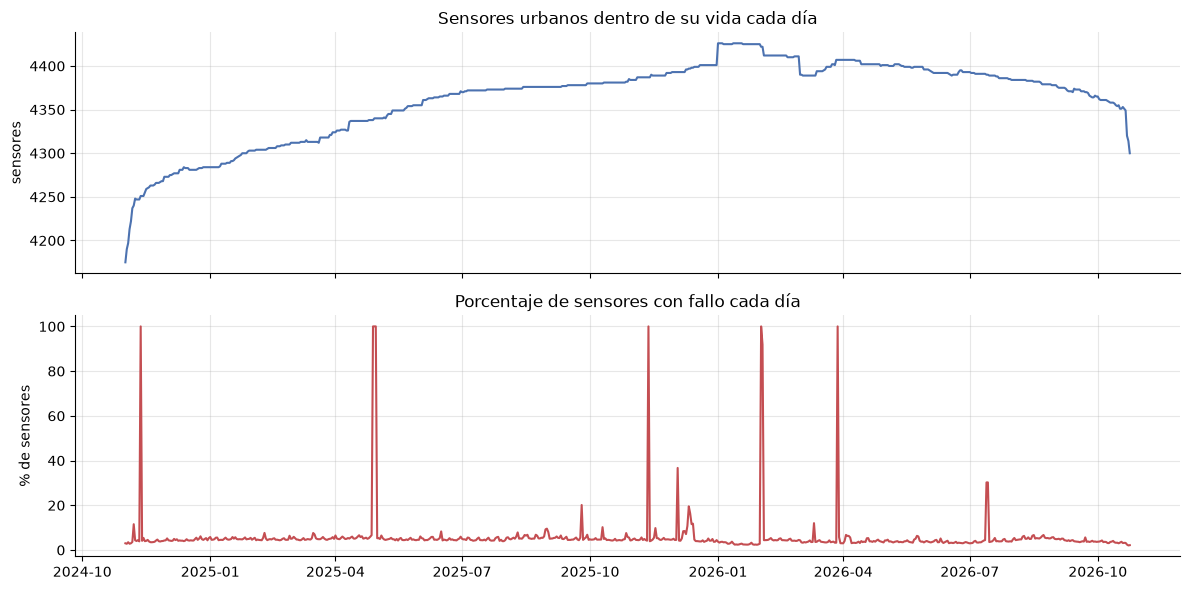

In [15]:
por_dia = p.groupby("ds").agg(sensores=("id", "size"), pct_fallo=("fallo", "mean"))
por_dia["pct_fallo"] *= 100

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(por_dia.index, por_dia["sensores"], color="#4C72B0")
ax[0].set(title="Sensores urbanos dentro de su vida cada día", ylabel="sensores")
ax[1].plot(por_dia.index, por_dia["pct_fallo"], color="#C44E52")
ax[1].set(title="Porcentaje de sensores con fallo cada día", ylabel="% de sensores")
plt.tight_layout()
por_dia.sort_values("pct_fallo", ascending=False).head(8)

In [16]:
CAIDA_GENERAL = 50  # % de sensores con fallo el mismo día
dias_caida = por_dia.index[por_dia["pct_fallo"] > CAIDA_GENERAL]
print("Días de caída general (> 50 % de sensores con fallo):", [f"{d:%Y-%m-%d}" for d in dias_caida])
p[p["ds"].isin(dias_caida)].groupby("ds")["estado"].value_counts().unstack(fill_value=0)

Días de caída general (> 50 % de sensores con fallo): ['2024-11-12', '2025-04-28', '2025-04-29', '2025-04-30', '2025-11-12', '2026-02-01', '2026-02-02', '2026-03-28']


estado,correcto,incompleto,sin datos,todo a cero
ds,,,,
2024-11-12,0,4194,55,2
2025-04-28,0,4194,105,39
2025-04-29,0,4038,277,25
2025-04-30,0,4215,108,17
2025-11-12,0,4268,92,27
2026-02-01,0,399,4022,1
2026-02-02,359,3934,102,27
2026-03-28,0,4290,83,34


**Lectura.** Los días de caída general fallan prácticamente todos los sensores a la vez, sobre todo como días
*incompletos*: se pierden horas de datos en toda la red. El caso más claro es el **28, 29 y 30 de abril de 2025**, el
**apagón eléctrico** de la península. El 1 de febrero de 2026 la red apenas entregó datos. Son incidencias del
sistema, no averías de un sensor, así que:
- **no penalizan a ningún sensor** al medir su fiabilidad (sección 5.3);
- se tendrán en cuenta como días anómalos al construir la serie diaria, porque su intensidad está infravalorada.

### 5.2 Enero de 2026: huecos rellenados con ceros
El mapa de la sección 5.4 muestra que en enero de 2026 casi no faltan datos, ni siquiera en sensores que el resto del
año fallan mucho. Se compara mes a mes cuántas lecturas llegan y cuántas son cero.

,lecturas_por_sensor_dia,pct_ceros
mes,,
2025-11-01,93.39,1.89
2025-12-01,92.90,1.93
2026-01-01,95.94,5.05
2026-02-01,93.11,3.54
2026-03-01,91.84,3.57


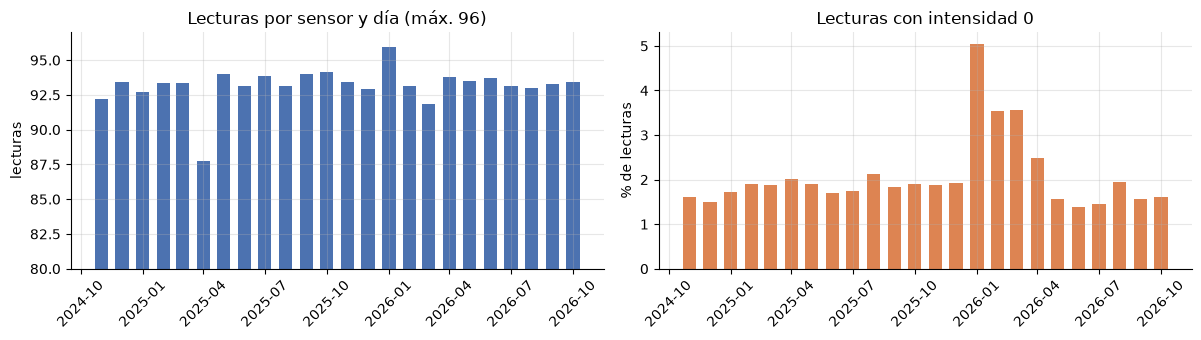

In [17]:
mensual = con.sql("""
    SELECT date_trunc('month', fecha) AS mes,
           count(*) / count(DISTINCT (id, CAST(fecha AS DATE))) AS lecturas_por_sensor_dia,
           avg((intensidad = 0)::INT) * 100 AS pct_ceros
    FROM urb GROUP BY 1 ORDER BY 1
""").df().set_index("mes")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(mensual.index, mensual["lecturas_por_sensor_dia"], width=20, color="#4C72B0")
ax[0].set(title="Lecturas por sensor y día (máx. 96)", ylabel="lecturas", ylim=(80, 97))
ax[1].bar(mensual.index, mensual["pct_ceros"], width=20, color="#DD8452")
ax[1].set(title="Lecturas con intensidad 0", ylabel="% de lecturas")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
mensual.loc["2025-11":"2026-03"]

**Lectura.** En enero de 2026 llegan casi todas las lecturas, pero el porcentaje de ceros se dispara: **ese mes la
fuente rellenó con 0 los cuartos de hora que faltaban** en lugar de no publicarlos. Es la trampa del handout
**"ceros por sensor caído ≠ calle vacía"** en estado puro. Por eso no basta con contar filas: las reglas de *todo a
cero* y *ceros de día* convierten esos ceros en lo que son, días con fallo.

### 5.3 Por sensor
La fiabilidad de cada sensor se mide **sin los días de caída general**.

In [18]:
def racha_max(fallos: pd.Series) -> int:
    """Días seguidos con fallo más largos de la serie."""
    return int(fallos.groupby((~fallos).cumsum()).sum().max())


p["caida_general"] = p["ds"].isin(dias_caida)
p["fallo_sensor"] = p["fallo"] & ~p["caida_general"]

sensor = p.groupby("id").agg(dias_vida=("ds", "size"), dias_fallo=("fallo_sensor", "sum"))
sensor["pct_fallo"] = sensor["dias_fallo"] / sensor["dias_vida"] * 100
sensor["racha_max"] = p.sort_values(["id", "ds"]).groupby("id")["fallo_sensor"].apply(racha_max)
sensor["vida_completa"] = (vida["primero"] == DIAS[0]) & (vida["ultimo"] == DIAS[-1])

tramos = pd.cut(sensor["pct_fallo"], [-0.01, 0, 1, 5, 20, 50, 100],
                labels=["0 % (nunca falla)", "≤ 1 %", "1 – 5 %", "5 – 20 %", "20 – 50 %", "> 50 %"])
n = len(sensor)
print(f"Sensores urbanos en entrenamiento:          {n:,}")
print(f"Fallan al menos un día:                     {(sensor['dias_fallo'] > 0).sum():,} ({(sensor['dias_fallo'] > 0).mean():.1%})")
print(f"Fallan más del 5 % de los días de su vida:  {(sensor['pct_fallo'] > 5).sum():,} ({(sensor['pct_fallo'] > 5).mean():.1%})")
print(f"Con alguna racha de más de 7 días caído:    {(sensor['racha_max'] > 7).sum():,}")
print(f"Con datos todo el periodo (vida completa):  {sensor['vida_completa'].sum():,}")
pd.DataFrame({"sensores": tramos.value_counts().sort_index(),
              "%": tramos.value_counts(normalize=True).sort_index() * 100})

Sensores urbanos en entrenamiento:          4,499
Fallan al menos un día:                     4,329 (96.2%)
Fallan más del 5 % de los días de su vida:  918 (20.4%)
Con alguna racha de más de 7 días caído:    1,202
Con datos todo el periodo (vida completa):  4,045


,sensores,%
pct_fallo,,
0 % (nunca falla),170,3.78
≤ 1 %,2585,57.46
1 – 5 %,826,18.36
5 – 20 %,607,13.49
20 – 50 %,187,4.16
> 50 %,124,2.76


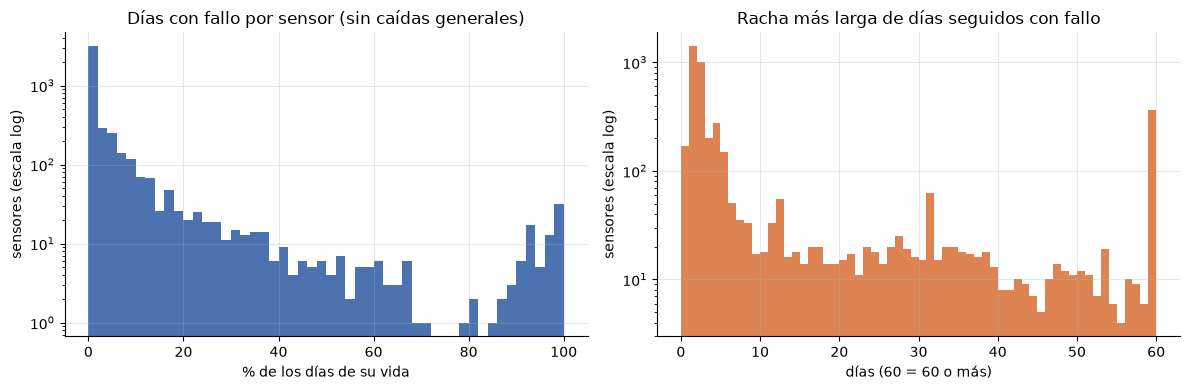

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(sensor["pct_fallo"], bins=50, color="#4C72B0")
ax[0].set(title="Días con fallo por sensor (sin caídas generales)", xlabel="% de los días de su vida",
          ylabel="sensores (escala log)", yscale="log")
ax[1].hist(sensor["racha_max"].clip(upper=60), bins=60, color="#DD8452")
ax[1].set(title="Racha más larga de días seguidos con fallo", xlabel="días (60 = 60 o más)",
          ylabel="sensores (escala log)", yscale="log")
plt.tight_layout()

### 5.4 Mapa de estados

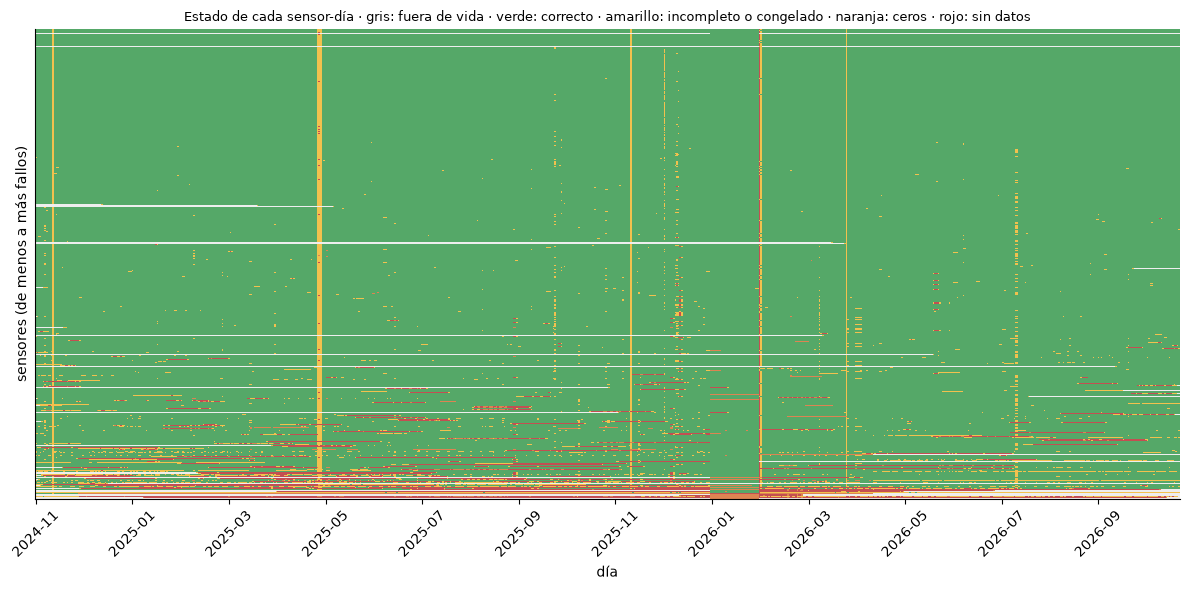

In [20]:
codigo = {"correcto": 0, "incompleto": 1, "valor congelado": 1, "ceros de día": 2, "todo a cero": 2,
          "sin lecturas válidas": 2, "sin datos": 3}
mapa = (panel[["id", "ds"]].merge(p[["id", "ds", "estado"]], how="left")
        .assign(v=lambda d: d["estado"].map(codigo).fillna(-1))
        .pivot(index="id", columns="ds", values="v")
        .loc[sensor.sort_values("pct_fallo").index])

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(mapa.values, aspect="auto", interpolation="nearest", vmin=-1, vmax=3,
          cmap=ListedColormap(["#EEEEEE", "#55A868", "#F2C14E", "#DD8452", "#C44E52"]))
ax.set_title("Estado de cada sensor-día · gris: fuera de vida · verde: correcto · amarillo: incompleto o "
             "congelado · naranja: ceros · rojo: sin datos", fontsize=9)
ax.set(xlabel="día", ylabel="sensores (de menos a más fallos)")
marcas = np.arange(0, mapa.shape[1], 61)
ax.set_xticks(marcas, [f"{d:%Y-%m}" for d in mapa.columns[marcas]], rotation=45)
ax.set_yticks([])
ax.grid(False)
plt.tight_layout()

## 6. Altas y bajas: cruce con el fichero de ubicación

El portal publica cada mes la lista de puntos de medida activos. Un sensor que aparece a mitad de periodo es un
**alta**; uno que deja de aparecer, una **baja**. Solo se usan las fichas hasta **septiembre de 2026**: la de
octubre incluye la semana de test.

In [21]:
fichas = []
for f in sorted((BRUTO / "ubicacion").glob("*.parquet")):
    t = pd.read_parquet(f)
    t.columns = [c.strip().strip('"').lower() for c in t.columns]
    t["mes"] = pd.Period(f.stem, freq="M")
    fichas.append(t)
ubic = pd.concat(fichas, ignore_index=True)
ubic["tipo_elem"] = ubic["tipo_elem"].astype(str).str.strip()
ULTIMO_MES_FICHA = pd.Period(TEST_INICIO, freq="M") - 1
ubic = ubic[(ubic["tipo_elem"] == "URB") & (ubic["mes"] <= ULTIMO_MES_FICHA)]
meses_ficha = pd.period_range(DESDE, ULTIMO_MES_FICHA, freq="M")

en_ficha = ubic.groupby("id")["mes"].agg(primer_mes="min", ultimo_mes="max", meses="nunique")
en_ficha["alta"] = en_ficha["primer_mes"] > meses_ficha[0]
en_ficha["baja"] = en_ficha["ultimo_mes"] < meses_ficha[-1]
en_ficha["estable"] = en_ficha["meses"] == len(meses_ficha)

ids_datos, ids_ficha = set(sensor.index), set(en_ficha.index)
pd.Series({
    f"Puntos URB en las fichas ({meses_ficha[0]} → {meses_ficha[-1]})": len(ids_ficha),
    "  · presentes todos los meses (estables)": en_ficha["estable"].sum(),
    "  · altas durante el periodo": en_ficha["alta"].sum(),
    "  · bajas durante el periodo": en_ficha["baja"].sum(),
    "Sensores con datos y con ficha": len(ids_datos & ids_ficha),
    "Sensores con datos pero sin ficha": len(ids_datos - ids_ficha),
    "Puntos con ficha pero sin ningún dato": len(ids_ficha - ids_datos),
}).to_frame("puntos")

,puntos
Puntos URB en las fichas (2024-11 → 2026-09),4653
· presentes todos los meses (estables),4493
· altas durante el periodo,131
· bajas durante el periodo,30
Sensores con datos y con ficha,4489
Sensores con datos pero sin ficha,10
Puntos con ficha pero sin ningún dato,164


In [22]:
# Metadatos de cada sensor: su última ficha publicada
info = (ubic.sort_values("mes").groupby("id")
        .agg(distrito=("distrito", "last"), nombre=("nombre", "last"),
             longitud=("longitud", "last"), latitud=("latitud", "last")))
sensor = sensor.join(en_ficha[["alta", "baja", "estable"]]).join(info)
sensor["distrito"] = sensor["distrito"].astype("Int64")

pd.crosstab(sensor["estable"].fillna(False).map({True: "estable en fichas", False: "alta/baja o sin ficha"}),
            sensor["vida_completa"].map({True: "datos todo el periodo", False: "datos parciales"}),
            margins=True, margins_name="total")

vida_completa,datos parciales,datos todo el periodo,total
estable,,,
alta/baja o sin ficha,131,0,131
estable en fichas,323,4045,4368
total,454,4045,4499


**Lectura.** Las fichas de ubicación y los datos cuentan casi la misma historia: los sensores que se dan de alta o de
baja en las fichas son los que tienen datos solo una parte del periodo. Para modelizar 2 años se necesitan sensores
**estables en las fichas y con datos de principio a fin**.

## 7. Selección de los 200 sensores

**Criterio**, calculado solo con entrenamiento:
1. **Estable**: aparece en todas las fichas de ubicación y tiene datos el primer y el último día (sin altas ni bajas).
2. **Fiable**: como mucho un 2 % de días con fallo y ninguna racha de más de 3 días seguidos con fallo. Con esto, los
   huecos que queden se pueden imputar sin inventar semanas enteras.
3. **Representativo**: entre los que cumplen 1 y 2, **muestreo aleatorio estratificado por distrito** (semilla fija),
   proporcional al número de candidatos de cada distrito. No se cogen los 200 "más perfectos" porque podrían
   concentrarse en ciertas zonas y la muestra no representaría la ciudad.

In [23]:
UMBRAL_FALLO, RACHA_MAX = 2.0, 3

candidatos = sensor[sensor["estable"].fillna(False) & sensor["vida_completa"]
                    & (sensor["pct_fallo"] <= UMBRAL_FALLO) & (sensor["racha_max"] <= RACHA_MAX)
                    & sensor["distrito"].notna()]
print(f"Candidatos: {len(candidatos):,} de {len(sensor):,} sensores urbanos")
assert len(candidatos) >= N_SENSORES, "Pocos candidatos: relajar UMBRAL_FALLO o RACHA_MAX"

# Reparto proporcional por distrito (método del mayor resto)
prop = candidatos["distrito"].value_counts() / len(candidatos) * N_SENSORES
cuota = np.floor(prop).astype(int)
cuota[(prop - cuota).sort_values(ascending=False).index[: N_SENSORES - cuota.sum()]] += 1

seleccion = pd.concat([g.sample(cuota[d], random_state=SEMILLA) for d, g in candidatos.groupby("distrito")])
print(f"Seleccionados: {len(seleccion)} sensores en {seleccion['distrito'].nunique()} distritos")

Candidatos: 2,596 de 4,499 sensores urbanos
Seleccionados: 200 sensores en 21 distritos


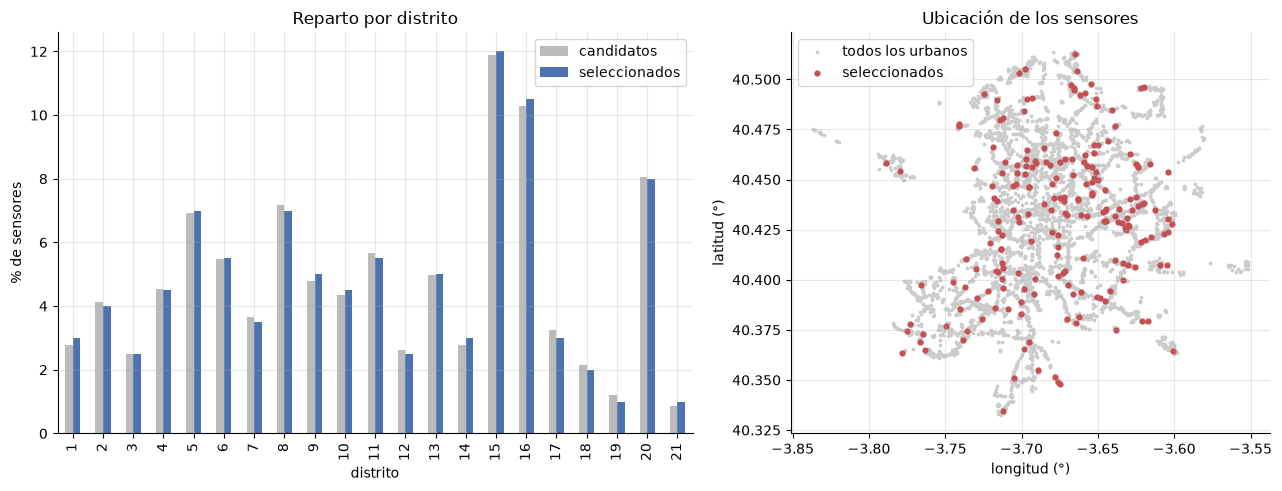

In [24]:
reparto = pd.DataFrame({"candidatos": candidatos["distrito"].value_counts(normalize=True) * 100,
                        "seleccionados": seleccion["distrito"].value_counts(normalize=True) * 100}).sort_index()
reparto.index = reparto.index.astype(int)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
reparto.plot.bar(ax=ax[0], color=["#BBBBBB", "#4C72B0"])
ax[0].set(title="Reparto por distrito", xlabel="distrito", ylabel="% de sensores")
todos = sensor.dropna(subset=["latitud"])
ax[1].scatter(todos["longitud"], todos["latitud"], s=3, color="#CCCCCC", label="todos los urbanos")
ax[1].scatter(seleccion["longitud"], seleccion["latitud"], s=12, color="#C44E52", label="seleccionados")
ax[1].set(title="Ubicación de los sensores", xlabel="longitud (°)", ylabel="latitud (°)")
ax[1].set_aspect(1 / np.cos(np.radians(40.4)))
ax[1].legend()
plt.tight_layout()

### 7.1 Fallos en los 200 seleccionados

In [25]:
ps = p[p["id"].isin(seleccion.index)]
fallos_sel = ps["estado"].value_counts().to_frame("sensor_dias")
fallos_sel["%"] = fallos_sel["sensor_dias"] / len(ps) * 100
print(f"{ps['id'].nunique()} sensores × {ps['ds'].nunique()} días = {len(ps):,} sensor-días")
fallos_sel

200 sensores × 723 días = 144,600 sensor-días


,sensor_dias,%
estado,,
correcto,142534,98.57
incompleto,1825,1.26
sin datos,222,0.15
valor congelado,16,0.01
ceros de día,2,0.00
todo a cero,1,0.00


In [26]:
salida = seleccion[["distrito", "nombre", "latitud", "longitud", "pct_fallo", "racha_max"]].sort_index()
salida.to_csv(SELECCION / "sensores_200.csv")
print(f"Guardado {SELECCION / 'sensores_200.csv'} (no se versiona: se regenera con este notebook)")
salida.head()

Guardado C:\Users\Caju\proyectos_esic\entrega-e1\e1\data\seleccion\sensores_200.csv (no se versiona: se regenera con este notebook)


,distrito,nombre,latitud,longitud,pct_fallo,racha_max
id,,,,,,
3396,7,CEA BERMUDEZ E-O (SAN GABRIEL - SAN FRANCISCO ...,40.44,-3.72,0.14,1
3433,3,Dr. Esquerdo S-N - Valderribas-Garibay,40.40,-3.67,0.28,2
3475,1,Gran Via San Francisco S-N (Isabel Tintero-Agu...,40.41,-3.71,0.28,1
3484,17,AV. REAL PINTO N-S(RESINA-SAN EZEQUIEL),40.33,-3.71,0.55,2
3498,9,Av.Gregorio del Amo O-E - Estación Metro - Ju...,40.45,-3.72,0.14,1


## 8. Conclusiones

**Tamaño.** 24 meses en bruto ocupan 1,07 GB en Parquet. Sin la semana de test son 314 M de lecturas de 15 minutos,
de las que 287 M (91 %) son de **4.499 puntos urbanos**. Los puntos de la M-30 se descartan porque el encargo es sobre
vía urbana.

**Calidad del bruto.** No hay duplicados ni nulos explícitos (solo 2 `NaN` en `ocupacion`, columna que no usamos).
La columna `error` no informa (siempre `N`) y `vmed` vale siempre 0 en urbanos. Hay 1.312 lecturas imposibles
(> 15.000 veh/h, incluido el código 99999) que se descartan.

**Los nulos están escondidos.** No aparecen como `NaN`, sino de tres formas:
- **Días sin fila:** 2,4 % de los sensor-días dentro de la vida de cada sensor.
- **Cuartos de hora perdidos:** en los días con datos llega el 97 % de lo esperado, y al 26 % de esos días le falta
  al menos uno.
- **Ceros que son fallos:** días enteros a cero y ceros en horas de día. En enero de 2026 la fuente rellenó los huecos
  con ceros.

**¿Cuántos sensores fallan?** Casi todos alguna vez: el 96 % tiene al menos un día con fallo, sin contar las caídas
generales. Pero la mayoría falla poco: el **61 % falla en ≤ 1 % de sus días**. El problema se concentra en un
**20 % de sensores que fallan más del 5 % de los días**, y 1.202 tienen alguna caída de más de una semana.

**Caídas generales.** Hay 8 días en los que falla toda la red a la vez, entre ellos el **apagón del 28-30 de abril de
2025**. No son culpa de ningún sensor, pero esos días la intensidad está infravalorada y habrá que tratarlos al
construir la serie.

**Altas y bajas.** Cruzando con el fichero de ubicación: 131 altas y 30 bajas en el periodo. 4.045 sensores son
estables y tienen datos de principio a fin.

**Selección.** Hay 2.596 candidatos estables y fiables (≤ 2 % de días con fallo y sin caídas de más de 3 días). De
ellos se eligen **200 sensores en los 21 distritos**, al azar y en proporción a cada distrito. En esos 200, el 98,6 %
de los sensor-días es correcto; casi todo el resto son las caídas generales, que afectan a todos por igual.

**Siguiente paso.** Construir la serie diaria `y` de los 200 sensores en formato largo (`unique_id`, `ds`, `y`),
decidir cómo imputar los días con fallo y las caídas generales, y empezar el análisis de la serie (apartado B).